# Exploration: Business Understanding and Problem FOrmulation

**Business context**: Chocolate distribution centre

**Candidate locations**: Aveiro and Viseu, Portugal

**Official target**: T2 - Heat Stress Event

**Business question**: *Which location may require more cooling effort during relatively hot periods?*

## Notebook Purpose

This notebook establishes the business context, defines what the available weather data can and cannot tell us, and explores the two candidate locations before streaming models are developed in later notebooks.

The analysis is about weather-related external heat exposure. The dataset does not contain warehouse indoor temperatures, insulation, building orientation, refrigeration-system performance, energy consumption, product temperature, stock levels, or cooling costs. Therefore, outdoor weather can be used as a proxy for potential cooling pressure, but it cannot directly measure the actual cooling effort or prove which facility would cost less to operate.

The official target T2 defines a relatively high-temperature event using a threshold estimated from pooled warm-up observations for both cities. The threshold must be estimated once and frozen before evaluation. The target is not a universal food-safety limit or a direct measurement of chocolate-storage risk.

## Table of Contents

Business understanding and decision context
Problem formulation and analytical questions
Data source, locations, and historical period
Imports and configuration
Data collection
Data structure and initial inspection
Data quality and chronological integrity
Descriptive statistics
Distribution and extreme-value analysis
Temporal patterns: long-term, seasonal, and hourly
Relationships between weather variables
Comparative summary
Exploration findings to carry forward
Limitations and hand-off to the streaming notebooks

## 1. Business Understanding

### 1.1 Operational context


A chocolate distribution centre needs to maintain appropriate storage and handling conditions for temperature-sensitive products. Periods of relatively high outdoor temperature may increase the heat entering a facility and may increase the demand placed on cooling systems. The extent of that effect depends on the building, equipment, operations, and indoor conditions, none of which are directly observed in this dataset.

### 1.2 Decision to support

Compare Aveiro and Viseu on the weather-related heat-exposure dimension to identify which location experiences more frequent, intense, or persistent relatively hot conditions.

### 1.3 Analytical Objective

Characterise and compare the two hourly weather streams, then define a leakage-free T2 event that later notebooks can monitor and predict incrementally.

### 1.4 What counts as evidence?

The exploration should examine:

- the distribution of hourly temperature, including upper quantiles and extremes;

- the frequency and persistence of relatively hot periods once the official T2 threshold is constructed;

- seasonal and time-of-day patterns;

- overnight cooling, as a potentially useful indicator of how much temperatures fall outside the daytime peak;

- related weather variables as context, without treating correlation as proof of cooling demand.

## 2. Problem Formulation

### 2.1 Unit of analysis

One observation represents one hourly weather record for one candidate city.

### 2.2 Descriptive versus predictive questions

**Descriptive/business questions**

- Which city has higher temperatures in the upper tail of its distribution?

- How often do T2 events occur in each city?

- Are events clustered into sustained periods, and how does this vary by season?

- How do temperatures change during the day and overnight?

**Predictive/technical questions**

- How accurately and efficiently can incremental models predict whether the current hour will be a T2 event, using only information available before that hour?

### 2.3 Leakage pevention

When predicting y_t, do not use current temperature T_t as an input because it defines the target. Valid predictors can include lagged weather values and rolling features calculated only from observations before t. 

Later streaming evaluation must follow PREDICT → EVALUATE → LEARN.

### 2.4 Success Criteria

A useful analysis should produce:

1. a documented, chronologically valid dataset for each city;
2. comparable descriptive evidence for both cities;
3. a clear target definition and warm-up policy;
4. evidence on event frequency and persistence;
5. explicit limitations linking outdoor weather to actual facility cooling requirements.

## 3. Data Source, Locations and Period

Hourly historical weather observations are retrieved from Open-Meteo using the coordinates defined in config.py.

- Candidate A: Aveiro

- Candidate B: Viseu

- Period: use the configured START_DATE and END_DATE; report the actual dates observed in the retrieved data rather than relying on a hard-coded description.

- Granularity: hourly

- Variables: temperature, relative humidity, precipitation, wind speed, night minimum temperature, city, and timestamp.

## 4. Imports and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns


from config import (
    CITIES,
    START_DATE,
    END_DATE,
    WEATHER_COLUMNS,
    NIGHT_START_HOUR,
    NIGHT_END_HOUR,
    NIGHT_HOURS,
    REQUIRED_COLUMNS,
    PHYSICAL_BOUNDS,
)

from exploration_functions import (
    fetch_open_meteo_data,
    plot_multivariate_timeseries,
    plot_correlation_heatmaps,
    plot_outlier_boxplots,
    plot_distribution_overlays,
    plot_ecdf_comparison,
    plot_qq_comparison,
    plot_precipitation_wind_detail,
    export_figure
    
)

## 5. Data Collection

- 5.1 Save original API response
- 5.2 Extract hourly observations into a DataFrame
- 5.3 Convert the timestamp column into datetime
- 5.4 Sort observations chronologically
- 5.5 historical period: **Year 2023**
- 5.6 Save processed data

In [2]:
weather_data = {}

for city_name, location in CITIES.items():
    weather_data[city_name] = fetch_open_meteo_data(
        latitude=location["latitude"],
        longitude=location["longitude"],
        start_date=START_DATE,
        end_date=END_DATE,
        city_name=city_name,
    )

df_aveiro_raw = weather_data["Aveiro"]
df_viseu_raw = weather_data["Viseu"]

Aveiro: loading cached data from C:\Users\Rafael\Documents\GitHub\DSM_Practical_Assignment_I\data\processed\aveiro.csv
Viseu: loading cached data from C:\Users\Rafael\Documents\GitHub\DSM_Practical_Assignment_I\data\processed\viseu.csv


## 6. Data Structure and Initial Inspection



In [3]:
for city_name, df in weather_data.items():
    print(f"\n{'=' * 65}")
    print(f"EXPLORATORY DATA ANALYSIS — {city_name.upper()}")
    print("=" * 65)

    print(f"Number of observations: {len(df):,}")
    print(f"Number of columns: {df.shape[1]}")
    print(f"First observation: {df['time'].min()}")
    print(f"Last observation: {df['time'].max()}")
    print(f"Number of unique timestamps: {df['time'].nunique():,}")

    print("\nDataFrame information:")
    df.info()

    print("\nFirst five observations:")
    display(df.head())


EXPLORATORY DATA ANALYSIS — AVEIRO
Number of observations: 96,408
Number of columns: 7
First observation: 2013-01-01 00:00:00
Last observation: 2023-12-31 23:00:00
Number of unique timestamps: 96,408

DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96408 entries, 0 to 96407
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   time                   96408 non-null  datetime64[ns]
 1   temperature            96408 non-null  float64       
 2   relative_humidity      96408 non-null  int64         
 3   precipitation          96408 non-null  float64       
 4   wind_speed             96408 non-null  float64       
 5   night_min_temperature  96408 non-null  float64       
 6   city                   96408 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 5.1+ MB

First five observations:


,time,temperature,relative_humidity,precipitation,wind_speed,night_min_temperature,city
0,2013-01-01 00:00:00,12.2,92,0.0,4.2,10.1,Aveiro
1,2013-01-01 01:00:00,9.8,96,0.0,9.5,10.1,Aveiro
2,2013-01-01 02:00:00,9.4,97,0.0,14.0,10.1,Aveiro
3,2013-01-01 03:00:00,10.0,95,0.0,13.3,10.1,Aveiro
4,2013-01-01 04:00:00,10.3,95,0.0,12.4,10.1,Aveiro



EXPLORATORY DATA ANALYSIS — VISEU
Number of observations: 96,408
Number of columns: 7
First observation: 2013-01-01 00:00:00
Last observation: 2023-12-31 23:00:00
Number of unique timestamps: 96,408

DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96408 entries, 0 to 96407
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   time                   96408 non-null  datetime64[ns]
 1   temperature            96408 non-null  float64       
 2   relative_humidity      96408 non-null  int64         
 3   precipitation          96408 non-null  float64       
 4   wind_speed             96408 non-null  float64       
 5   night_min_temperature  96408 non-null  float64       
 6   city                   96408 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 5.1+ MB

First five observations:


,time,temperature,relative_humidity,precipitation,wind_speed,night_min_temperature,city
0,2013-01-01 00:00:00,7.6,99,0.1,7.2,7.3,Viseu
1,2013-01-01 01:00:00,7.7,99,0.0,5.5,7.3,Viseu
2,2013-01-01 02:00:00,7.9,99,0.0,4.6,7.3,Viseu
3,2013-01-01 03:00:00,8.1,99,0.0,3.6,7.3,Viseu
4,2013-01-01 04:00:00,8.0,99,0.0,2.7,7.3,Viseu


In [4]:
for city_name, df in weather_data.items():
    print(f"\n{city_name.upper()} - DESCRIPTIVE STATISTICS")

    display(
        df[WEATHER_COLUMNS]
        .describe(
            percentiles=[
                0.01, 0.05, 0.25,
                0.50, 0.75, 0.95, 0.99,
            ]
        )
        .T
        .round(2)
    )


AVEIRO - DESCRIPTIVE STATISTICS


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
temperature,96408.0,15.62,5.18,-1.5,4.2,7.4,12.2,15.5,18.8,24.4,29.7,38.8
relative_humidity,96408.0,79.15,16.07,13.0,31.0,48.0,69.0,83.0,92.0,99.0,100.0,100.0
precipitation,96408.0,0.13,0.51,0.0,0.0,0.0,0.0,0.0,0.0,0.7,2.5,15.5
wind_speed,96408.0,14.44,7.94,0.0,1.6,3.6,8.2,13.4,19.5,28.9,36.3,62.7
night_min_temperature,96408.0,12.77,4.22,-0.5,2.7,5.4,9.7,13.2,16.1,18.7,21.0,27.7



VISEU - DESCRIPTIVE STATISTICS


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
temperature,96408.0,14.24,7.15,-3.4,0.9,3.9,9.0,13.3,18.7,27.7,32.5,40.2
relative_humidity,96408.0,73.28,21.08,8.0,22.0,33.0,58.0,78.0,92.0,99.0,100.0,100.0
precipitation,96408.0,0.13,0.51,0.0,0.0,0.0,0.0,0.0,0.0,0.7,2.6,12.7
wind_speed,96408.0,10.03,5.71,0.0,1.3,2.7,5.7,8.8,13.5,20.9,26.3,45.0
night_min_temperature,96408.0,10.38,5.26,-3.4,-0.5,1.8,6.4,10.3,14.4,18.8,22.2,28.5


## 7. Data Quality and Chronological Integrity

In [5]:
for city_name, df in weather_data.items():
    print(f"\n{city_name.upper()} - NIGHT MIN TEMPERATURE CHECK")

    col = "night_min_temperature"
    first_valid = df.loc[df[col].notna(), "time"].min()

    print(f"Missing values: {df[col].isna().sum():,}")
    print(f"First valid timestamp: {first_valid}")
    print(f"Night window: {NIGHT_START_HOUR:02d}:00 -> {NIGHT_END_HOUR:02d}:00 "
          f"({NIGHT_HOURS} h)")

    # The value must be constant within each 06:00-to-06:00 block
    # (it only changes when a new night completes at 06:00)
    changes = df[col].ne(df[col].shift()) & df[col].notna()
    change_hours = df.loc[changes, "time"].dt.hour.value_counts()
    print("Hours at which the value changes (expect only 6):")
    print(change_hours.to_dict())

    # Inspect one day around the boundary
    sample_day = df["time"].dt.normalize().iloc[72]
    mask = df["time"].between(sample_day, sample_day + pd.Timedelta(hours=23))
    display(df.loc[mask, ["time", "temperature", col]].iloc[::3])


AVEIRO - NIGHT MIN TEMPERATURE CHECK
Missing values: 0
First valid timestamp: 2013-01-01 00:00:00
Night window: 21:00 -> 06:00 (9 h)
Hours at which the value changes (expect only 6):
{6: 3937, 0: 1}


,time,temperature,night_min_temperature
72,2013-01-04 00:00:00,7.7,7.2
75,2013-01-04 03:00:00,6.8,7.2
78,2013-01-04 06:00:00,6.2,6.4
81,2013-01-04 09:00:00,5.7,6.4
84,2013-01-04 12:00:00,11.8,6.4
87,2013-01-04 15:00:00,15.6,6.4
90,2013-01-04 18:00:00,15.0,6.4
93,2013-01-04 21:00:00,8.6,6.4



VISEU - NIGHT MIN TEMPERATURE CHECK
Missing values: 0
First valid timestamp: 2013-01-01 00:00:00
Night window: 21:00 -> 06:00 (9 h)
Hours at which the value changes (expect only 6):
{6: 3956, 0: 1}


,time,temperature,night_min_temperature
72,2013-01-04 00:00:00,4.9,5.8
75,2013-01-04 03:00:00,3.6,5.8
78,2013-01-04 06:00:00,2.8,3.0
81,2013-01-04 09:00:00,2.3,3.0
84,2013-01-04 12:00:00,8.3,3.0
87,2013-01-04 15:00:00,11.8,3.0
90,2013-01-04 18:00:00,9.8,3.0
93,2013-01-04 21:00:00,5.5,3.0


## 8. Distributions


In [6]:
weather_data = {
    "Aveiro": df_aveiro_raw,
    "Viseu": df_viseu_raw,
}

weather_variables = [
    "temperature",
    "relative_humidity",
    "precipitation",
    "wind_speed",
]

for city, df in weather_data.items():
    plot_multivariate_timeseries(
       df, city, weather_variables,
       threshold=globals().get("TAU_T_HOT"),
       warmup_end=globals().get("WARMUP_END"),
       export_name=f"timeseries_{city.lower()}_full",   # <- new
   )

Full-resolution figure saved to figures\timeseries_aveiro_full.html


Full-resolution figure saved to figures\timeseries_viseu_full.html


- Temperature: Viseu shows a wider temperature range with lower minimums, whereas Aveiro has a narrower distribution centered around slightly warmer mid-range temperatures.   

- Humidity: Both cities experience predominantly high humidity levels, though Viseu has slightly higher density at lower humidity percentages.   

- Precipitation: Both locations exhibit identical, heavily right-skewed distributions dominated by near-zero precipitation values (dry conditions).   

- Wind Speed: Aveiro consistently records higher wind speeds with a much longer right tail extending past 50, reflecting its typical coastal environment compared to Viseu.   

In [7]:
cities = list(weather_data)
core_variables = [c for c in WEATHER_COLUMNS if c != "precipitation"]

plot_distribution_overlays(weather_data, core_variables).show()
plot_ecdf_comparison(weather_data, core_variables).show()
plot_qq_comparison(weather_data, cities[0], cities[1], core_variables).show()
plot_precipitation_wind_detail(weather_data).show()

## 9. Extreme Observations

In [ ]:
fig = plot_outlier_boxplots(weather_data, WEATHER_COLUMNS)
fig.show()
export_figure(plot_outlier_boxplots(weather_data, WEATHER_COLUMNS, max_outliers=None),
                "outlier_boxplots_full")

Full-resolution figure saved to figures\outlier_boxplots_full.html


WindowsPath('figures/outlier_boxplots_full.html')

- Temperature: Aveiro shows a slightly higher median temperature. Viseu displays a lower 25th percentile and minimum temperature, while both districts share similar upper outliers peaking around 40°C.   

- Humidity: Aveiro has a higher median humidity and a narrower interquartile range. Viseu exhibits a wider spread toward lower humidity levels, though both top out at 100%.   

- Precipitation: Both districts have medians and interquartile ranges concentrated at 0. Aveiro presents more extreme high-precipitation outliers reaching up to about 15.5 compared to Viseu's maximum outliers near 13.  

- Wind Speed: Aveiro has a significantly higher median and interquartile range than Viseu. Aveiro also features substantial high-value outliers extending beyond 60, whereas Viseu's outliers cap out around 45. 

## 10. Temporal Patterns

### 10.1 Daily temperature evolution

Daily averages smooth hourly noise. Daily maxima help reveal the hottest conditions. Both are useful, but neither should replace the hourly stream used for the later T2 model.

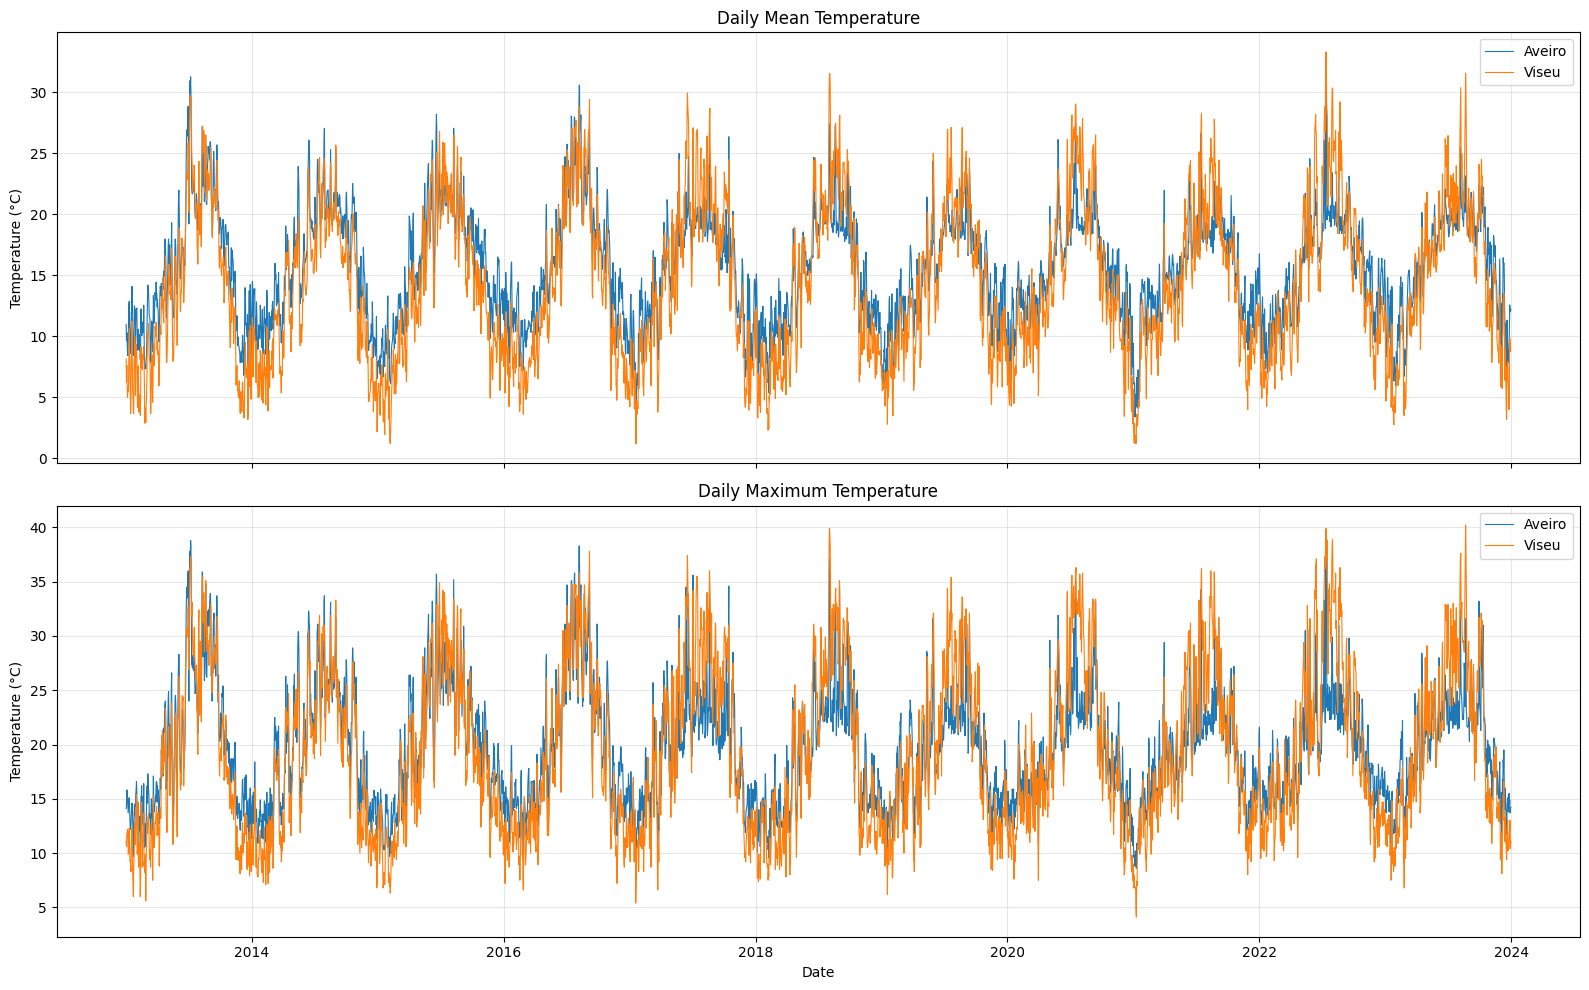

In [9]:
daily_data = {}

for city_name, df in weather_data.items():
    daily_data[city_name] = (
        df.set_index("time")
        .resample("D")
        .agg(
            temperature_mean=("temperature", "mean"),
            temperature_max=("temperature", "max"),
            temperature_min=("temperature", "min"),
            humidity_mean=("relative_humidity", "mean"),
            precipitation_sum=("precipitation", "sum"),
            wind_speed_mean=("wind_speed", "mean"),
        )
    )

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

for city_name, daily in daily_data.items():
    axes[0].plot(
        daily.index,
        daily["temperature_mean"],
        label=city_name,
        linewidth=0.8,
    )

    axes[1].plot(
        daily.index,
        daily["temperature_max"],
        label=city_name,
        linewidth=0.8,
    )

axes[0].set_title("Daily Mean Temperature")
axes[1].set_title("Daily Maximum Temperature")

for ax in axes:
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

- Strong Seasonality: Both cities exhibit consistent, highly regular annual temperature cycles with pronounced summer peaks and winter troughs spanning from 2013 to 2024.   

- Wider Extremes in Viseu: Viseu experiences greater seasonal temperature variability, consistently dropping to lower minimums in the winter and rising to higher maximums in the summer.   

- Coastal Moderation in Aveiro: Aveiro displays a more tempered climate with milder winters and cooler summer peaks, characteristic of a coastal influence.   

- Stable Interannual Trends: The overall year-to-year temperature patterns and ranges remain stable across the decade without major long-term shifts visible in the daily means or maximums. 

### 10.2 Monthly seasonal profile

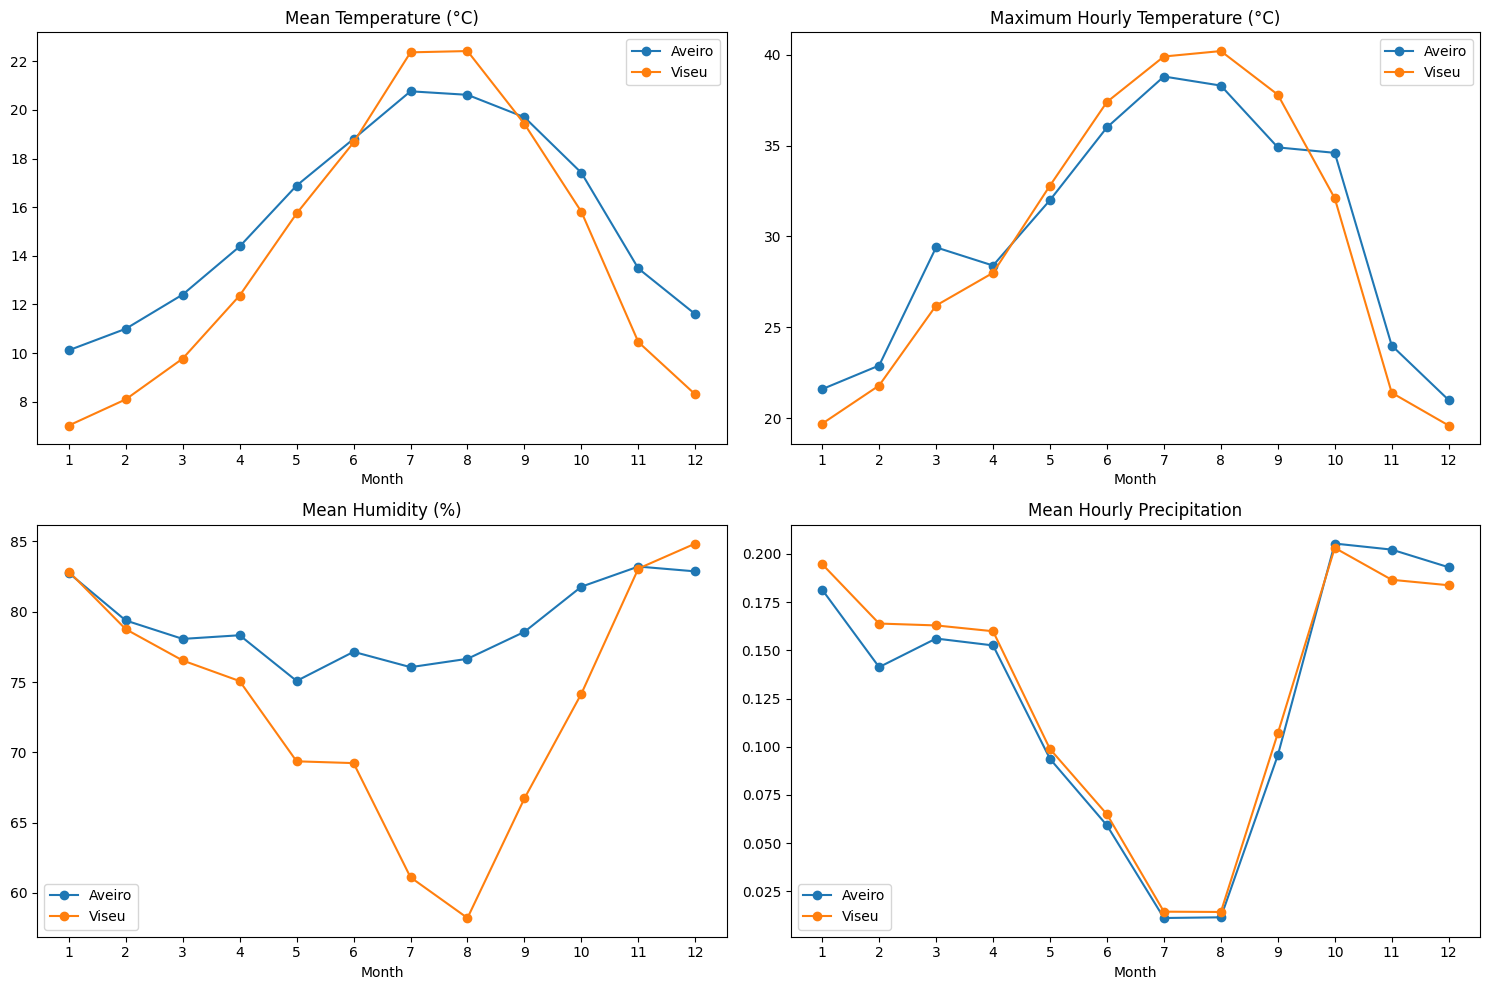

In [10]:
monthly_data = {}

for city_name, df in weather_data.items():
    temp_df = df.assign(month=df["time"].dt.month)

    monthly_data[city_name] = temp_df.groupby("month").agg(
        mean_temperature=("temperature", "mean"),
        maximum_temperature=("temperature", "max"),
        mean_humidity=("relative_humidity", "mean"),
        mean_precipitation=("precipitation", "mean"),
        mean_wind_speed=("wind_speed", "mean"),
    )

monthly_plots = [
    ("mean_temperature", "Mean Temperature (°C)"),
    ("maximum_temperature", "Maximum Hourly Temperature (°C)"),
    ("mean_humidity", "Mean Humidity (%)"),
    ("mean_precipitation", "Mean Hourly Precipitation"),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (variable, title) in zip(axes.flat, monthly_plots):
    for city_name, monthly in monthly_data.items():
        ax.plot(
            monthly.index,
            monthly[variable],
            marker="o",
            label=city_name,
        )

    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.set_xticks(range(1, 13))
    ax.legend()

plt.tight_layout()
plt.show()

- Mean and Maximum Temperature: Both cities peak in July and August. Viseu reaches higher summer maximums and drops to lower winter minimums, while Aveiro shows a more moderated coastal profile with warmer winters and cooler mid-summer peaks.   

- Mean Humidity: Aveiro stays relatively steady throughout the year (roughly 75% to 84%). Viseu exhibits strong seasonal variation, dropping sharply during the dry summer months (down to nearly 58% in August) before rising in winter.   

- Mean Hourly Precipitation: Both locations share an identical seasonal rainfall trend, experiencing wet winters/autumns and a pronounced dry season from June through August, with July and August recording near-zero means.  

### 10.3 Hour-of-day profile

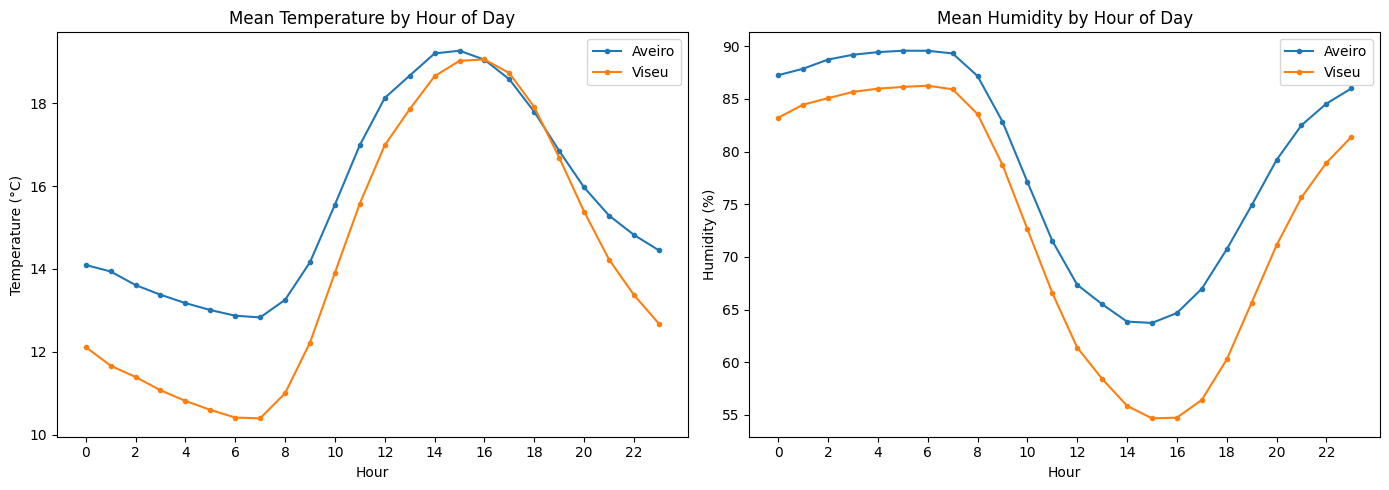

In [11]:
hourly_profiles = {}

for city_name, df in weather_data.items():
    hourly_profiles[city_name] = (
        df.assign(hour=df["time"].dt.hour)
        .groupby("hour")
        .agg(
            mean_temperature=("temperature", "mean"),
            mean_humidity=("relative_humidity", "mean"),
            mean_wind_speed=("wind_speed", "mean"),
        )
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for city_name, profile in hourly_profiles.items():
    axes[0].plot(
        profile.index,
        profile["mean_temperature"],
        marker="o",
        markersize=3,
        label=city_name,
    )

    axes[1].plot(
        profile.index,
        profile["mean_humidity"],
        marker="o",
        markersize=3,
        label=city_name,
    )

axes[0].set_title("Mean Temperature by Hour of Day")
axes[0].set_ylabel("Temperature (°C)")

axes[1].set_title("Mean Humidity by Hour of Day")
axes[1].set_ylabel("Humidity (%)")

for ax in axes:
    ax.set_xlabel("Hour")
    ax.set_xticks(range(0, 24, 2))
    ax.legend()

plt.tight_layout()
plt.show()

- Diurnal Temperature Cycle: Both cities follow a classic daily pattern, reaching minimum temperatures around 6:00–7:00 AM and peaking in the early afternoon between 3:00 PM and 4:00 PM.   

- Temperature Gap: Aveiro remains consistently warmer than Viseu during night and morning hours, whereas Viseu catches up during the peak afternoon heat.   

- Diurnal Humidity Cycle: Inverse to temperature, humidity peaks in the early morning (~6:00 AM) and drops to its daily low during mid-afternoon (~3:00 PM–4:00 PM).   

- Overall Humidity Offset: Aveiro maintains higher average humidity across all hours of the day compared to Viseu.

## 11. Relationships Between Weather Variables

In [12]:
fig = plot_correlation_heatmaps(weather_data, WEATHER_COLUMNS)
fig.show()

- Inverse Temperature-Humidity Relationship: Both cities exhibit a moderate-to-strong negative correlation between temperature and humidity (Aveiro at -0.51, Viseu stronger at -0.69), consistent with daily and seasonal heating cycles.   

- Weak Temperature-Precipitation Link: Temperature shows virtually no linear relationship with precipitation in either district, with correlation coefficients near zero (-0.05 for Aveiro and -0.08 for Viseu).   

- Precipitation and Wind Speed: Both locations show a slight positive correlation between precipitation and wind speed (0.23 in Aveiro and 0.27 in Viseu), indicating that windier hours tend to align somewhat with wet conditions.   

- Wind Speed and Temperature Differences: Aveiro displays a weak positive correlation between wind speed and temperature (0.11), whereas Viseu shows no correlation between the two (-0.01).  

Correlation caveat: Correlation describes a statistical relationship, not causation. In particular, the dataset cannot establish how much cooling energy a warehouse would consume. Temperature is the primary variable for the official T2 target; other variables may provide context or support later predictive features if their temporal alignment is valid.

## 12. Comparative Summary

In [13]:
summary_rows = []

for city_name, df in weather_data.items():
    summary_rows.append({
        "District": city_name,
        "Observations": len(df),
        "Mean temperature (°C)": df["temperature"].mean(),
        "Median temperature (°C)": df["temperature"].median(),
        "Temperature std (°C)": df["temperature"].std(),
        "Minimum temperature (°C)": df["temperature"].min(),
        "Maximum temperature (°C)": df["temperature"].max(),
        "Mean humidity (%)": df["relative_humidity"].mean(),
        "Mean precipitation": df["precipitation"].mean(),
        "Total precipitation": df["precipitation"].sum(),
        "Mean wind speed": df["wind_speed"].mean(),
    })

final_summary = pd.DataFrame(summary_rows).set_index("District")

display(final_summary.round(2))

,Observations,Mean temperature (°C),Median temperature (°C),Temperature std (°C),Minimum temperature (°C),Maximum temperature (°C),Mean humidity (%),Mean precipitation,Total precipitation,Mean wind speed
District,,,,,,,,,,
Aveiro,96408,15.62,15.5,5.18,-1.5,38.8,79.15,0.13,12064.1,14.44
Viseu,96408,14.24,13.3,7.15,-3.4,40.2,73.28,0.13,12463.1,10.03


Concluding:

- Observation Count: Both datasets are balanced with an identical sample size of 96,408 observations each.

- Temperature: Aveiro is warmer on average (15.62°C mean / 15.50°C median) and more thermally stable (5.18°C std), whereas Viseu experiences greater temperature spread (7.15°C std) with lower minimums (-3.40°C) and higher maximums (40.20°C).

- Humidity: Aveiro exhibits significantly higher average humidity (79.15%) than Viseu (73.28%).

- Precipitation: Total and mean hourly precipitation are virtually identical between districts, both averaging 0.13 mm/h and accumulating approximately 12,064 mm to 12,463 mm overall.

- Wind Speed: Aveiro records notably higher average wind speeds (14.44) compared to Viseu (10.03).

## 13. Limitations

1. Outdoor versus indoor conditions: weather observations are not warehouse temperature measurements.

2. No direct cooling-demand data: electricity consumption, HVAC load, cooling-system capacity, insulation, building design, and operating schedules are not included.

3. Proxy target: T2 identifies relatively hot conditions according to a pooled warm-up quantile. It is not a chocolate safety threshold.

4. Historical evidence: past weather patterns do not guarantee future conditions.

5. Limited decision dimensions: the analysis does not compare rent, labour, transport, taxes, infrastructure, regulation, or proximity to customers.

6. Feature availability: derived variables such as night_min_temperature require careful timing checks before being used in a prediction model.

7. Correlation: associations between weather variables do not prove a causal effect on cooling requirements.